In [7]:
import pandas as pd

df = pd.read_csv("/content/HRAST.csv")

print("Dataset shape:", df.shape)
display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/HRAST.csv'

In [ ]:
print("Column names:")
for i, col in enumerate(df.columns, start=1):
    print(i, "→", col)

Column names:
1 → id
2 → review
3 → Unnamed: 2
4 → positive
5 → negative
6 → neutral
7 → Clean
8 → Comfort
9 → Facilities/Amenities
10 → Location
11 → Restaurant (dinner)
12 → Staff
13 → View (Balcony)
14 → Breakfast
15 → Room
16 → Pool
17 → Beach
18 → Bathroom/Shower (toilet)
19 → Bar
20 → Bed
21 → Parking
22 → Noise
23 → Reception-checkin
24 → Lift
25 → Value for money
26 → Wi-Fi
27 → Generic
28 → Aspect


In [ ]:
print("DATASET INFORMATION")
print("=" * 50)

df.info()

print("\nMISSING VALUES")
print("=" * 50)

print(df.isnull().sum())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23113 entries, 0 to 23112
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   id                        23113 non-null  int64 
 1   review                    23113 non-null  object
 2   Unnamed: 2                79 non-null     object
 3   positive                  23113 non-null  int64 
 4   negative                  23113 non-null  int64 
 5   neutral                   23113 non-null  int64 
 6   Clean                     23113 non-null  int64 
 7   Comfort                   23113 non-null  int64 
 8   Facilities/Amenities      23113 non-null  int64 
 9   Location                  23113 non-null  object
 10  Restaurant (dinner)       23113 non-null  int64 
 11  Staff                     23113 non-null  int64 
 12  View (Balcony)            23113 non-null  int64 
 13  Breakfast                 23113 non-null  int64 
 14  Ro

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


SENTIMENT DISTRIBUTION
Positive: 11819
Negative: 10504
Neutral : 794

SENTIMENT PERCENTAGES
Positive: 51.14 %
Negative: 45.45 %
Neutral : 3.44 %


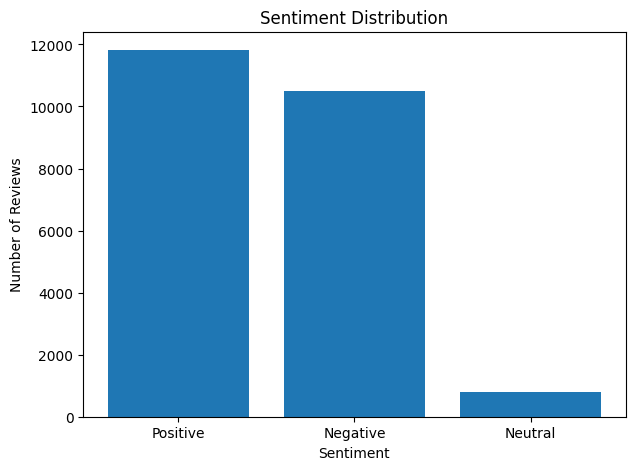

In [ ]:
print("SENTIMENT DISTRIBUTION")
print("=" * 40)

print("Positive:", df["positive"].sum())
print("Negative:", df["negative"].sum())
print("Neutral :", df["neutral"].sum())
print("\nSENTIMENT PERCENTAGES")
print("=" * 40)

print("Positive:", round(df["positive"].mean() * 100, 2), "%")
print("Negative:", round(df["negative"].mean() * 100, 2), "%")
print("Neutral :", round(df["neutral"].mean() * 100, 2), "%")
import matplotlib.pyplot as plt

sentiment_counts = [
    df["positive"].sum(),
    df["negative"].sum(),
    df["neutral"].sum()
]

sentiments = ["Positive", "Negative", "Neutral"]

plt.figure(figsize=(7, 5))
plt.bar(sentiments, sentiment_counts)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [ ]:
sentiment_columns = ["positive", "negative", "neutral"]

df["sentiment_count"] = df[sentiment_columns].sum(axis=1)

print("Sentiment label combinations:")
print(df["sentiment_count"].value_counts().sort_index())

print("\nRows with multiple sentiment labels:")
display(
    df[df["sentiment_count"] > 1][
        ["review", "positive", "negative", "neutral"]
    ]
)

Sentiment label combinations:
sentiment_count
1    23109
2        4
Name: count, dtype: int64

Rows with multiple sentiment labels:


,review,positive,negative,neutral
4556,Free parking in front of the hotel.,1,1,0
11601,Room is basic but spotless clean and comfortab...,1,0,1
15916,The kitchenette is very practical but could be...,1,0,1
18968,The staff at the front desk (made the impressi...,0,1,1


In [ ]:
# List of aspect columns
aspect_columns = [
    "Clean",
    "Comfort",
    "Facilities/Amenities",
    "Location",
    "Restaurant (dinner)",
    "Staff",
    "View (Balcony)",
    "Breakfast",
    "Room",
    "Pool",
    "Beach",
    "Bathroom/Shower (toilet)",
    "Bar",
    "Bed",
    "Parking",
    "Noise",
    "Reception-checkin",
    "Lift",
    "Value for money",
    "Wi-Fi",
    "Generic"
]

print("Number of aspects:", len(aspect_columns))

Number of aspects: 21


In [ ]:
print("Location column data type:")
print(df["Location"].dtype)

print("\nSample Location values:")
print(df["Location"].head(20).to_list())

print("\nUnique Location values:")
print(df["Location"].unique()[:20])

Location column data type:
object

Sample Location values:
['0', '0', '0', '1', '1', '0', '1', '1', '1', '1', '1', '1', '1', '1', '1', '0', '0', '0', '0', '0']

Unique Location values:
['0' '1' 'σ']


In [ ]:
print(df[aspect_columns].dtypes)

Clean                        int64
Comfort                      int64
Facilities/Amenities         int64
Location                    object
Restaurant (dinner)          int64
Staff                        int64
View (Balcony)               int64
Breakfast                    int64
Room                         int64
Pool                         int64
Beach                        int64
Bathroom/Shower (toilet)     int64
Bar                          int64
Bed                          int64
Parking                      int64
Noise                        int64
Reception-checkin            int64
Lift                         int64
Value for money              int64
Wi-Fi                        int64
Generic                      int64
dtype: object


In [ ]:
numeric_aspects = [
    col for col in aspect_columns
    if pd.api.types.is_numeric_dtype(df[col])
]

print("Numeric aspect columns:", len(numeric_aspects))
print(numeric_aspects)

aspect_counts = df[numeric_aspects].sum().sort_values(ascending=False)

print("\nASPECT DISTRIBUTION")
print("=" * 50)
print(aspect_counts)

Numeric aspect columns: 20
['Clean', 'Comfort', 'Facilities/Amenities', 'Restaurant (dinner)', 'Staff', 'View (Balcony)', 'Breakfast', 'Room', 'Pool', 'Beach', 'Bathroom/Shower (toilet)', 'Bar', 'Bed', 'Parking', 'Noise', 'Reception-checkin', 'Lift', 'Value for money', 'Wi-Fi', 'Generic']

ASPECT DISTRIBUTION
Room                        5004
Staff                       3804
Clean                       2927
Facilities/Amenities        2923
Comfort                     2562
Breakfast                   2539
Bathroom/Shower (toilet)    2346
Generic                     1973
Noise                       1604
Bed                         1480
Reception-checkin            953
Value for money              892
View (Balcony)               784
Parking                      541
Pool                         472
Bar                          322
Restaurant (dinner)          300
Lift                         291
Wi-Fi                        268
Beach                        188
dtype: int64


In [ ]:
location_anomaly = df[df["Location"] == "σ"]

print("Number of Location = 'σ' rows:", len(location_anomaly))

display(
    location_anomaly[
        ["id", "review", "Location", "positive", "negative", "neutral"]
    ]
)

Number of Location = 'σ' rows: 1


,id,review,Location,positive,negative,neutral
4633,4634,"Friendly staff , clean and great extras.",σ,1,0,0


In [ ]:
print(df["Location"].value_counts())

Location
0    18383
1     4729
σ        1
Name: count, dtype: int64


In [ ]:
# Temporarily convert Location's normal binary values for counting.
# Exclude the anomalous 'σ' rows for this analysis.

aspect_binary = df[aspect_columns].copy()

aspect_binary["Location"] = pd.to_numeric(
    aspect_binary["Location"],
    errors="coerce"
)

df["number_of_aspects"] = aspect_binary.sum(axis=1)

print("Number of aspects per sentence:")
print(
    df["number_of_aspects"]
    .value_counts()
    .sort_index()
)

Number of aspects per sentence:
number_of_aspects
0.0        4
1.0    13439
2.0     6716
3.0     2099
4.0      618
5.0      173
6.0       53
7.0        9
8.0        2
Name: count, dtype: int64


In [ ]:
multi_aspect_count = (df["number_of_aspects"] > 1).sum()
total = len(df)

print("Sentences with multiple aspects:", multi_aspect_count)
print("Percentage:", round(multi_aspect_count / total * 100, 2), "%")

Sentences with multiple aspects: 9670
Percentage: 41.84 %


In [ ]:
# Remove the temporary analysis column if present
# and create a clean binary copy for co-occurrence analysis.

aspect_binary = df[aspect_columns].copy()

aspect_binary["Location"] = pd.to_numeric(
    aspect_binary["Location"],
    errors="coerce"
).fillna(0)

aspect_binary = aspect_binary.astype(int)

print("Aspect matrix shape:", aspect_binary.shape)
print("\nTotal aspect annotations:", aspect_binary.sum().sum())

Aspect matrix shape: (23113, 21)

Total aspect annotations: 36902


In [ ]:
# Aspect co-occurrence matrix
co_occurrence = aspect_binary.T.dot(aspect_binary)

display(co_occurrence)

,Clean,Comfort,Facilities/Amenities,Location,Restaurant (dinner),Staff,View (Balcony),Breakfast,Room,Pool,...,Bathroom/Shower (toilet),Bar,Bed,Parking,Noise,Reception-checkin,Lift,Value for money,Wi-Fi,Generic
Clean,2927,488,250,398,6,449,43,154,1141,30,...,453,12,265,10,92,58,12,49,6,275
Comfort,488,2562,225,278,8,227,73,115,1451,34,...,354,7,825,20,80,20,15,59,11,176
Facilities/Amenities,250,225,2923,136,6,164,36,101,777,84,...,372,25,145,19,110,42,13,53,27,135
Location,398,278,136,4729,68,645,76,289,471,32,...,43,56,127,84,267,54,9,138,12,316
Restaurant (dinner),6,8,6,68,300,39,6,33,7,1,...,2,40,4,0,4,4,0,13,0,12
Staff,449,227,164,645,39,3804,30,375,382,22,...,69,50,106,42,61,415,11,59,16,249
View (Balcony),43,73,36,76,6,30,784,39,237,18,...,17,7,22,4,34,5,2,5,1,38
Breakfast,154,115,101,289,33,375,39,2539,196,14,...,34,64,55,23,27,28,6,222,7,77
Room,1141,1451,777,471,7,382,237,196,5004,27,...,462,17,362,19,378,77,33,153,23,278
Pool,30,34,84,32,1,22,18,14,27,472,...,11,10,12,2,12,7,0,18,1,19


In [ ]:
print(
    "Average aspects per sentence:",
    round(36902 / 23113, 2)
)

Average aspects per sentence: 1.6


In [ ]:
# Create the aspect matrix again

aspect_binary = df[aspect_columns].copy()

# Convert Location from '0'/'1'/'σ' to numeric
aspect_binary["Location"] = pd.to_numeric(
    aspect_binary["Location"],
    errors="coerce"
).fillna(0)

# Make sure all aspect columns are integers
aspect_binary = aspect_binary.astype(int)

# Create aspect co-occurrence matrix
co_occurrence = aspect_binary.T.dot(aspect_binary)

print("Co-occurrence matrix created successfully.")
print("Shape:", co_occurrence.shape)

Co-occurrence matrix created successfully.
Shape: (21, 21)


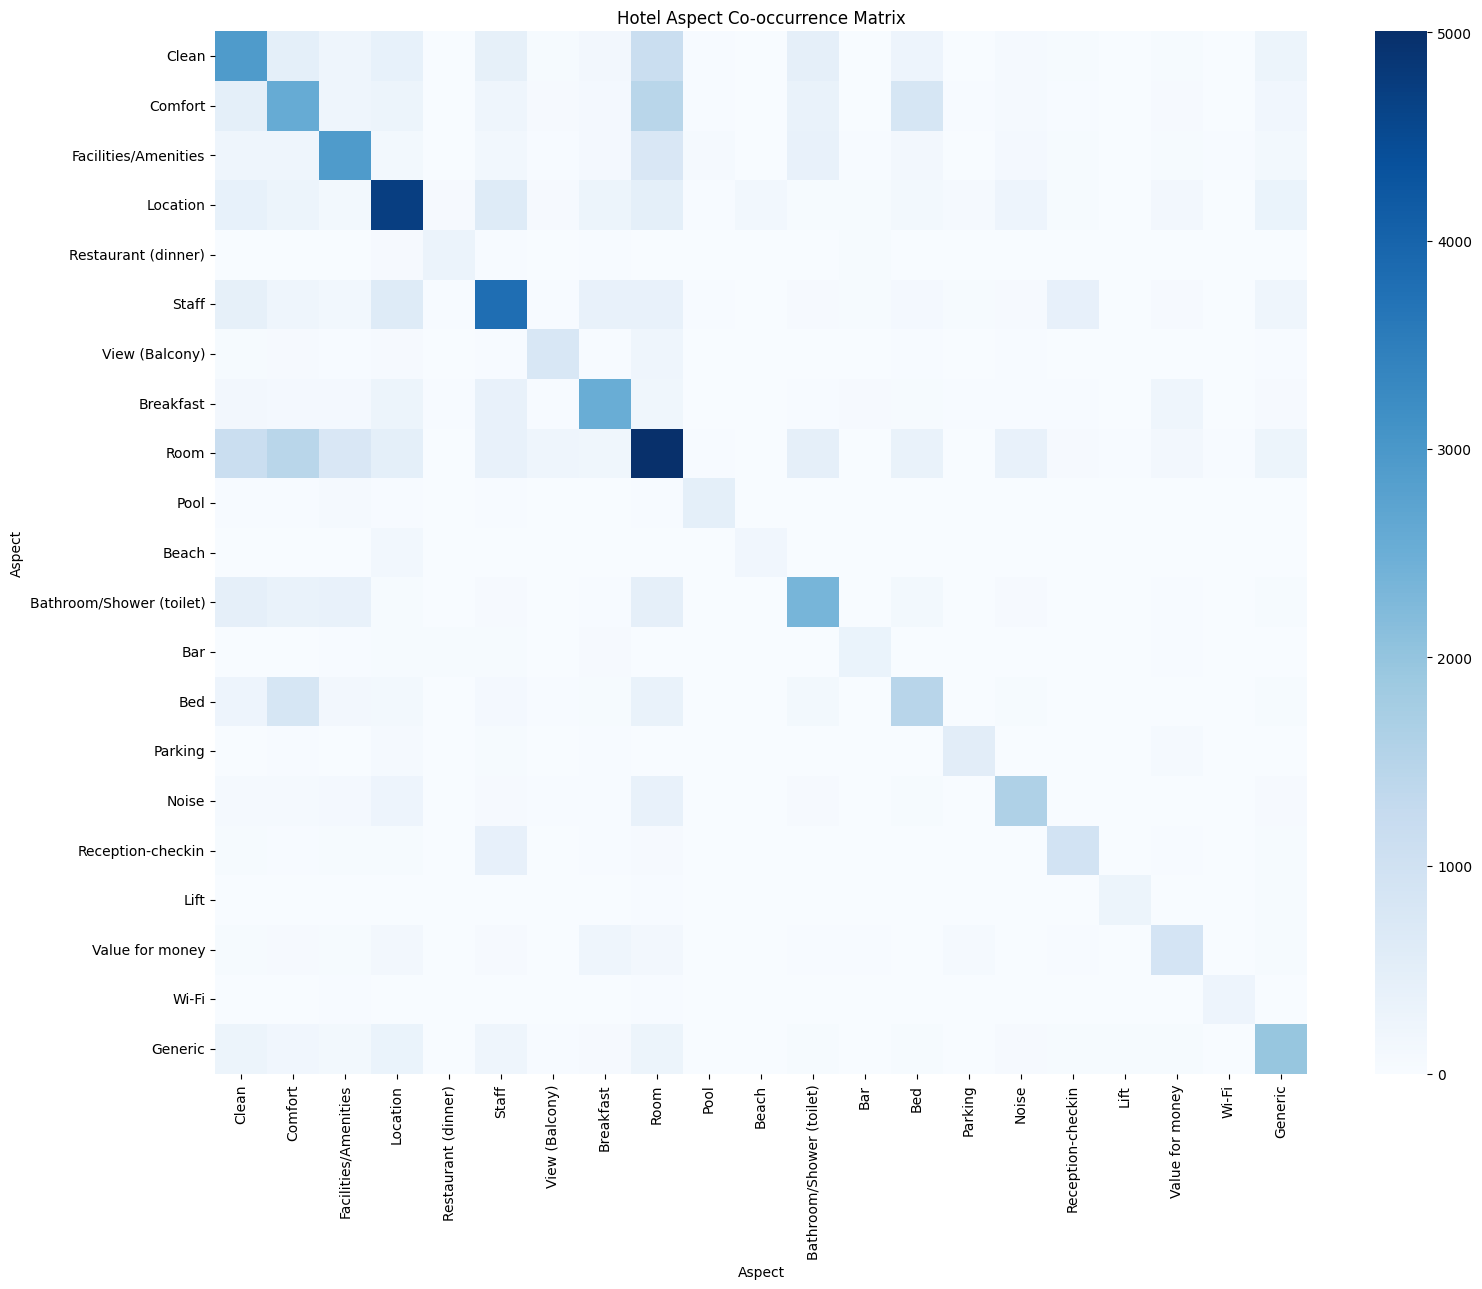

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 13))

sns.heatmap(
    co_occurrence,
    cmap="Blues",
    annot=False
)

plt.title("Hotel Aspect Co-occurrence Matrix")
plt.xlabel("Aspect")
plt.ylabel("Aspect")

plt.tight_layout()
plt.show()

In [ ]:
print(
    "Average aspects per sentence:",
    round(aspect_binary.sum(axis=1).mean(), 2)
)

Average aspects per sentence: 1.6


In [ ]:
df["review_length"] = df["review"].str.len()
df["word_count"] = df["review"].str.split().str.len()

print("Average characters:", round(df["review_length"].mean(), 2))
print("Minimum characters:", df["review_length"].min())
print("Maximum characters:", df["review_length"].max())

print("\nAverage words:", round(df["word_count"].mean(), 2))
print("Minimum words:", df["word_count"].min())
print("Maximum words:", df["word_count"].max())

Average characters: 57.57
Minimum characters: 6
Maximum characters: 678

Average words: 10.3
Minimum words: 2
Maximum words: 123


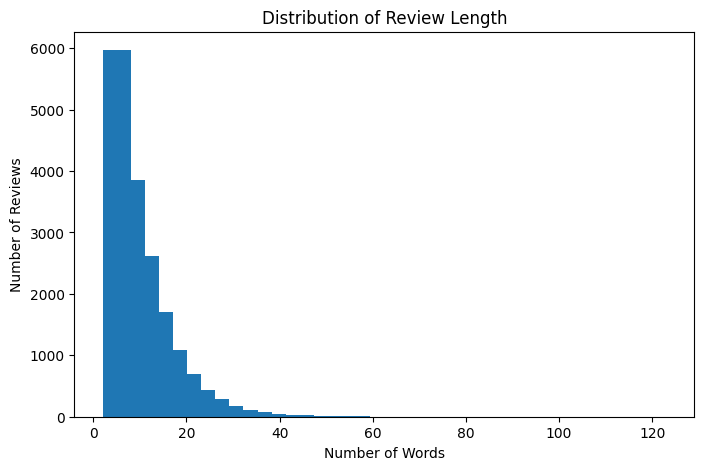

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df["word_count"], bins=40)

plt.title("Distribution of Review Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.show()

In [ ]:
import re
from collections import Counter

text = " ".join(df["review"].astype(str)).lower()

words = re.findall(r'\b[a-z]+\b', text)

word_counts = Counter(words)

print("Top 30 most frequent words:")
print(word_counts.most_common(30))



Top 30 most frequent words:
[('the', 19997), ('and', 9461), ('was', 6726), ('a', 5658), ('to', 5092), ('room', 5003), ('very', 4643), ('in', 4479), ('is', 3960), ('of', 3307), ('location', 2983), ('staff', 2721), ('not', 2545), ('breakfast', 2453), ('for', 2253), ('it', 2177), ('hotel', 1945), ('good', 1918), ('with', 1888), ('were', 1666), ('clean', 1659), ('we', 1560), ('nice', 1546), ('no', 1531), ('i', 1446), ('from', 1427), ('rooms', 1367), ('great', 1360), ('on', 1344), ('bathroom', 1310)]


In [ ]:
import nltk

nltk.download("stopwords")

from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

filtered_words = [
    word for word in words
    if word not in stop_words and len(word) > 2
]

filtered_counts = Counter(filtered_words)

print("Top 30 meaningful words:")
print(filtered_counts.most_common(30))

Top 30 meaningful words:
[('room', 5003), ('location', 2983), ('staff', 2721), ('breakfast', 2453), ('hotel', 1945), ('good', 1918), ('clean', 1659), ('nice', 1546), ('rooms', 1367), ('great', 1360), ('bathroom', 1310), ('friendly', 1116), ('small', 1082), ('bed', 971), ('comfortable', 966), ('shower', 907), ('helpful', 839), ('close', 793), ('really', 700), ('bit', 668), ('excellent', 641), ('well', 626), ('could', 619), ('city', 574), ('station', 553), ('also', 534), ('parking', 520), ('reception', 516), ('pool', 503), ('old', 501)]


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


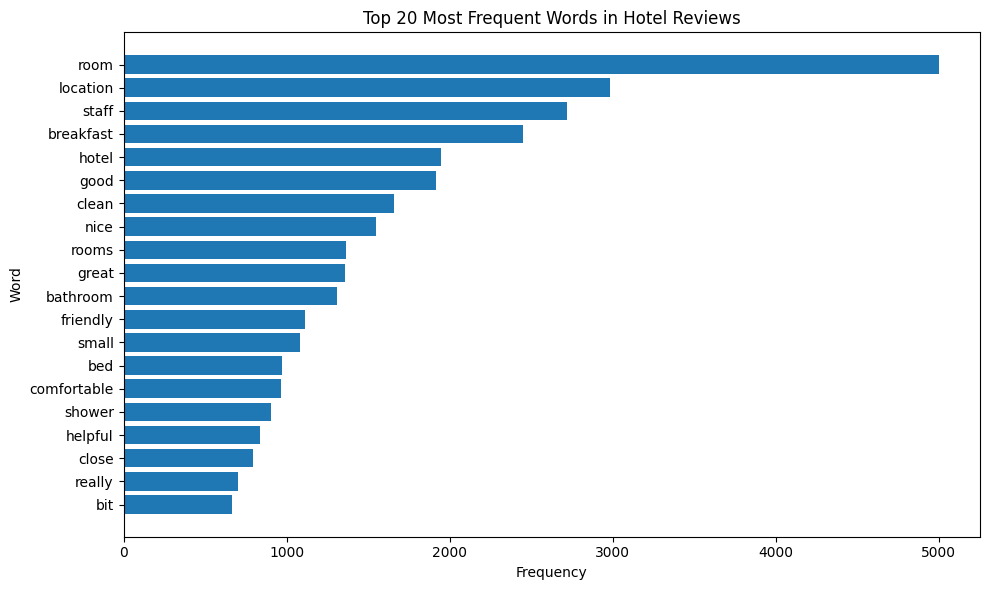

In [ ]:
top_words = filtered_counts.most_common(20)

words_list = [x[0] for x in top_words]
counts_list = [x[1] for x in top_words]

plt.figure(figsize=(10, 6))

plt.barh(words_list[::-1], counts_list[::-1])

plt.title("Top 20 Most Frequent Words in Hotel Reviews")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.tight_layout()
plt.show()

In [ ]:
df_clean = df.copy()

print("Original shape:", df_clean.shape)

Original shape: (23113, 32)


In [ ]:
eda_columns = [
    "sentiment_count",
    "number_of_aspects",
    "review_length",
    "word_count"
]

df_clean = df_clean.drop(
    columns=[col for col in eda_columns if col in df_clean.columns]
)

print("Shape after removing EDA columns:", df_clean.shape)

Shape after removing EDA columns: (23113, 28)


In [ ]:
df_clean = df_clean.drop(columns=["Unnamed: 2"])

print("Shape after removing Unnamed: 2:", df_clean.shape)

Shape after removing Unnamed: 2: (23113, 27)


In [ ]:
df_clean["Location"] = pd.to_numeric(
    df_clean["Location"],
    errors="coerce"
).fillna(0).astype(int)

print(df_clean["Location"].value_counts())

Location
0    18384
1     4729
Name: count, dtype: int64


In [ ]:
print("Aspect column data types:")
print(df_clean[aspect_columns].dtypes)



Aspect column data types:
Clean                       int64
Comfort                     int64
Facilities/Amenities        int64
Location                    int64
Restaurant (dinner)         int64
Staff                       int64
View (Balcony)              int64
Breakfast                   int64
Room                        int64
Pool                        int64
Beach                       int64
Bathroom/Shower (toilet)    int64
Bar                         int64
Bed                         int64
Parking                     int64
Noise                       int64
Reception-checkin           int64
Lift                        int64
Value for money             int64
Wi-Fi                       int64
Generic                     int64
dtype: object


In [ ]:
for col in aspect_columns:
    print(col, "→", sorted(df_clean[col].unique()))

Clean → [np.int64(0), np.int64(1)]
Comfort → [np.int64(0), np.int64(1)]
Facilities/Amenities → [np.int64(0), np.int64(1)]
Location → [np.int64(0), np.int64(1)]
Restaurant (dinner) → [np.int64(0), np.int64(1)]
Staff → [np.int64(0), np.int64(1)]
View (Balcony) → [np.int64(0), np.int64(1)]
Breakfast → [np.int64(0), np.int64(1)]
Room → [np.int64(0), np.int64(1)]
Pool → [np.int64(0), np.int64(1)]
Beach → [np.int64(0), np.int64(1)]
Bathroom/Shower (toilet) → [np.int64(0), np.int64(1)]
Bar → [np.int64(0), np.int64(1)]
Bed → [np.int64(0), np.int64(1)]
Parking → [np.int64(0), np.int64(1)]
Noise → [np.int64(0), np.int64(1)]
Reception-checkin → [np.int64(0), np.int64(1)]
Lift → [np.int64(0), np.int64(1)]
Value for money → [np.int64(0), np.int64(1)]
Wi-Fi → [np.int64(0), np.int64(1)]
Generic → [np.int64(0), np.int64(1)]


In [ ]:
multi_sentiment = df_clean[
    df_clean[["positive", "negative", "neutral"]].sum(axis=1) > 1
]

print("Number of multi-sentiment rows:", len(multi_sentiment))

display(
    multi_sentiment[
        ["id", "review", "positive", "negative", "neutral"]
    ]
)

Number of multi-sentiment rows: 4


,id,review,positive,negative,neutral
4556,4557,Free parking in front of the hotel.,1,1,0
11601,11602,Room is basic but spotless clean and comfortab...,1,0,1
15916,15917,The kitchenette is very practical but could be...,1,0,1
18968,18969,The staff at the front desk (made the impressi...,0,1,1


In [ ]:
display(
    multi_sentiment[
        ["review"] + aspect_columns
    ]
)

,review,Clean,Comfort,Facilities/Amenities,Location,Restaurant (dinner),Staff,View (Balcony),Breakfast,Room,...,Bathroom/Shower (toilet),Bar,Bed,Parking,Noise,Reception-checkin,Lift,Value for money,Wi-Fi,Generic
4556,Free parking in front of the hotel.,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,0
11601,Room is basic but spotless clean and comfortab...,1,1,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0
15916,The kitchenette is very practical but could be...,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
18968,The staff at the front desk (made the impressi...,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
import re

def clean_review(text):
    text = str(text).lower()
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    return text

df_clean["clean_review"] = df_clean["review"].apply(clean_review)

display(
    df_clean[["review", "clean_review"]].head(10)
)

,review,clean_review
0,1 elevator not working.,1 elevator not working.
1,1 euros to park per day on their own premises.,1 euros to park per day on their own premises.
2,1 hour queue to check-in.,1 hour queue to check-in.
3,1 min walk to metro entrance and also few min ...,1 min walk to metro entrance and also few min ...
4,1 minute walk from the main metro & train stat...,1 minute walk from the main metro & train stat...
5,1 person room was little.,1 person room was little.
6,1 stop (3 min ride) away from the airport.,1 stop (3 min ride) away from the airport.
7,1 stops right at the hotel.,1 stops right at the hotel.
8,10 mins to the historical centre along the riv...,10 mins to the historical centre along the riv...
9,10 mins walk to city or 10 mins bike ride to h...,10 mins walk to city or 10 mins bike ride to h...


In [ ]:
print("Missing original reviews:",
      df_clean["review"].isnull().sum())

print("Missing cleaned reviews:",
      df_clean["clean_review"].isnull().sum())

print("Empty cleaned reviews:",
      (df_clean["clean_review"].str.len() == 0).sum())

Missing original reviews: 0
Missing cleaned reviews: 0
Empty cleaned reviews: 0


In [ ]:
# Create a single sentiment label only for unambiguous rows

sentiment_cols = ["positive", "negative", "neutral"]

df_clean["sentiment_count"] = df_clean[sentiment_cols].sum(axis=1)

# Default: ambiguous
df_clean["sentiment_label"] = "ambiguous"

# Assign labels only where exactly one sentiment is present
df_clean.loc[
    (df_clean["positive"] == 1) &
    (df_clean["sentiment_count"] == 1),
    "sentiment_label"
] = "positive"

df_clean.loc[
    (df_clean["negative"] == 1) &
    (df_clean["sentiment_count"] == 1),
    "sentiment_label"
] = "negative"

df_clean.loc[
    (df_clean["neutral"] == 1) &
    (df_clean["sentiment_count"] == 1),
    "sentiment_label"
] = "neutral"

print(df_clean["sentiment_label"].value_counts())

sentiment_label
positive     11816
negative     10502
neutral        791
ambiguous        4
Name: count, dtype: int64


In [ ]:
print("Total rows:", len(df_clean))

print("\nSentiment labels:")
print(df_clean["sentiment_label"].value_counts())

print("\nAmbiguous rows:")
display(
    df_clean[df_clean["sentiment_label"] == "ambiguous"][
        ["id", "review", "positive", "negative", "neutral"]
    ]
)

Total rows: 23113

Sentiment labels:
sentiment_label
positive     11816
negative     10502
neutral        791
ambiguous        4
Name: count, dtype: int64

Ambiguous rows:


,id,review,positive,negative,neutral
4556,4557,Free parking in front of the hotel.,1,1,0
11601,11602,Room is basic but spotless clean and comfortab...,1,0,1
15916,15917,The kitchenette is very practical but could be...,1,0,1
18968,18969,The staff at the front desk (made the impressi...,0,1,1


In [ ]:
import re

def preprocess_text(text):
    text = str(text).lower()

    # Keep letters, numbers, apostrophes and spaces
    text = re.sub(r"[^a-z0-9'\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

df_clean["processed_review"] = df_clean["review"].apply(preprocess_text)

display(
    df_clean[["review", "processed_review"]].head(10)
)

,review,processed_review
0,1 elevator not working.,1 elevator not working
1,1 euros to park per day on their own premises.,1 euros to park per day on their own premises
2,1 hour queue to check-in.,1 hour queue to check in
3,1 min walk to metro entrance and also few min ...,1 min walk to metro entrance and also few min ...
4,1 minute walk from the main metro & train stat...,1 minute walk from the main metro train statio...
5,1 person room was little.,1 person room was little
6,1 stop (3 min ride) away from the airport.,1 stop 3 min ride away from the airport
7,1 stops right at the hotel.,1 stops right at the hotel
8,10 mins to the historical centre along the riv...,10 mins to the historical centre along the riv...
9,10 mins walk to city or 10 mins bike ride to h...,10 mins walk to city or 10 mins bike ride to h...


In [ ]:
print("Dataset shape:", df_clean.shape)

print("\nMissing processed reviews:",
      df_clean["processed_review"].isnull().sum())

print("Empty processed reviews:",
      (df_clean["processed_review"].str.len() == 0).sum())

print("\nAspect labels:")
print(df_clean[aspect_columns].shape)

print("\nSentiment labels:")
print(df_clean["sentiment_label"].value_counts())

Dataset shape: (23113, 31)

Missing processed reviews: 0
Empty processed reviews: 0

Aspect labels:
(23113, 21)

Sentiment labels:
sentiment_label
positive     11816
negative     10502
neutral        791
ambiguous        4
Name: count, dtype: int64


In [ ]:
duplicate_reviews = df_clean["review"].duplicated().sum()

print("Duplicate review texts:", duplicate_reviews)

Duplicate review texts: 8


In [ ]:
from sklearn.model_selection import train_test_split

# Create indices
indices = df_clean.index

# First split: 70% train, 30% temporary
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=df_clean["sentiment_label"]
)

# Second split: 15% validation, 15% test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42
)

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Test samples:", len(test_idx))

Training samples: 16179
Validation samples: 3467
Test samples: 3467


In [ ]:
print("TRAINING SENTIMENT")
print(df_clean.loc[train_idx, "sentiment_label"].value_counts(normalize=True))

print("\nVALIDATION SENTIMENT")
print(df_clean.loc[val_idx, "sentiment_label"].value_counts(normalize=True))

print("\nTEST SENTIMENT")
print(df_clean.loc[test_idx, "sentiment_label"].value_counts(normalize=True))

TRAINING SENTIMENT
sentiment_label
positive     0.511218
negative     0.454354
neutral      0.034242
ambiguous    0.000185
Name: proportion, dtype: float64

VALIDATION SENTIMENT
sentiment_label
positive     0.515143
negative     0.451687
neutral      0.032881
ambiguous    0.000288
Name: proportion, dtype: float64

TEST SENTIMENT
sentiment_label
positive    0.507355
negative    0.457168
neutral     0.035477
Name: proportion, dtype: float64


In [ ]:
X_aspect_train = df_clean.loc[train_idx, "processed_review"]
X_aspect_val = df_clean.loc[val_idx, "processed_review"]
X_aspect_test = df_clean.loc[test_idx, "processed_review"]

y_aspect_train = df_clean.loc[train_idx, aspect_columns]
y_aspect_val = df_clean.loc[val_idx, aspect_columns]
y_aspect_test = df_clean.loc[test_idx, aspect_columns]

In [ ]:
sentiment_df = df_clean[
    df_clean["sentiment_label"] != "ambiguous"
].copy()

print("Sentiment modeling samples:", len(sentiment_df))

In [ ]:
duplicate_reviews = df_clean[
    df_clean["review"].duplicated(keep=False)
].sort_values("review")

print("Number of duplicate review rows:", len(duplicate_reviews))

display(
    duplicate_reviews[
        ["id", "review", "positive", "negative", "neutral"] +
        aspect_columns
    ]
)

Number of duplicate review rows: 15


,id,review,positive,negative,neutral,Clean,Comfort,Facilities/Amenities,Location,Restaurant (dinner),...,Bathroom/Shower (toilet),Bar,Bed,Parking,Noise,Reception-checkin,Lift,Value for money,Wi-Fi,Generic
2477,2478,"Central location, cleanliness, friendliness of...",1,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2478,2479,"Central location, cleanliness, friendliness of...",1,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
7025,7026,It had a great location!,1,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
7026,7027,It had a great location!,1,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
13868,13869,The bathroom had an unpleasant odor coming.,0,1,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
13869,13870,The bathroom had an unpleasant odor coming.,0,1,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
13934,13935,The bathroom is very cramped.,0,1,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,0
13937,13938,The bathroom is very cramped.,0,1,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,0
19180,19181,The staff was friendly and helpful.,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
19181,19182,The staff was friendly and helpful.,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
df_model = df_clean.drop_duplicates(
    subset=["processed_review"],
    keep="first"
).copy()

print("Original rows:", len(df_clean))
print("Rows after duplicate removal:", len(df_model))
print("Rows removed:", len(df_clean) - len(df_model))

Original rows: 23113
Rows after duplicate removal: 23034
Rows removed: 79


In [ ]:
print(
    "Remaining duplicate processed reviews:",
    df_model["processed_review"].duplicated().sum()
)

Remaining duplicate processed reviews: 0


In [ ]:
# Recreate modeling dataframe from the cleaned dataset
df_model = df_clean.copy()

# Remove exact duplicate ORIGINAL review texts
df_model = df_model.drop_duplicates(
    subset=["review"],
    keep="first"
).copy()

print("Original rows:", len(df_clean))
print("Rows after exact duplicate removal:", len(df_model))
print("Rows removed:", len(df_clean) - len(df_model))

print(
    "Remaining duplicate review texts:",
    df_model["review"].duplicated().sum()
)

Original rows: 23113
Rows after exact duplicate removal: 23105
Rows removed: 8
Remaining duplicate review texts: 0


In [ ]:
from sklearn.model_selection import train_test_split

indices = df_model.index

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42
)

print("ASPECT DATASET SPLIT")
print("=" * 40)
print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))
print("Total:", len(train_idx) + len(val_idx) + len(test_idx))

ASPECT DATASET SPLIT
Training: 16173
Validation: 3466
Test: 3466
Total: 23105


In [ ]:
sentiment_model_df = df_model[
    df_model["sentiment_label"] != "ambiguous"
].copy()

print("Sentiment modeling samples:",
      len(sentiment_model_df))

Sentiment modeling samples: 23101


In [ ]:
sent_indices = sentiment_model_df.index

sent_train_idx, sent_temp_idx = train_test_split(
    sent_indices,
    test_size=0.30,
    random_state=42,
    stratify=sentiment_model_df.loc[
        sent_indices, "sentiment_label"
    ]
)

sent_val_idx, sent_test_idx = train_test_split(
    sent_temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=sentiment_model_df.loc[
        sent_temp_idx, "sentiment_label"
    ]
)

print("SENTIMENT DATASET SPLIT")
print("=" * 40)
print("Training:", len(sent_train_idx))
print("Validation:", len(sent_val_idx))
print("Test:", len(sent_test_idx))
print(
    "Total:",
    len(sent_train_idx)
    + len(sent_val_idx)
    + len(sent_test_idx)
)

SENTIMENT DATASET SPLIT
Training: 16170
Validation: 3465
Test: 3466
Total: 23101


In [ ]:
for name, idx in [
    ("TRAIN", sent_train_idx),
    ("VALIDATION", sent_val_idx),
    ("TEST", sent_test_idx)
]:
    print("\n" + name)
    print("=" * 30)

    print(
        sentiment_model_df.loc[
            idx, "sentiment_label"
        ].value_counts()
    )

    print("\nPercentages:")
    print(
        sentiment_model_df.loc[
            idx, "sentiment_label"
        ].value_counts(normalize=True) * 100
    )


TRAIN
sentiment_label
positive    8266
negative    7350
neutral      554
Name: count, dtype: int64

Percentages:
sentiment_label
positive    51.119357
negative    45.454545
neutral      3.426098
Name: proportion, dtype: float64

VALIDATION
sentiment_label
positive    1772
negative    1575
neutral      118
Name: count, dtype: int64

Percentages:
sentiment_label
positive    51.139971
negative    45.454545
neutral      3.405483
Name: proportion, dtype: float64

TEST
sentiment_label
positive    1772
negative    1575
neutral      119
Name: count, dtype: int64

Percentages:
sentiment_label
positive    51.125216
negative    45.441431
neutral      3.433353
Name: proportion, dtype: float64


In [ ]:
X_aspect_train = df_model.loc[
    train_idx, "processed_review"
]

X_aspect_val = df_model.loc[
    val_idx, "processed_review"
]

X_aspect_test = df_model.loc[
    test_idx, "processed_review"
]

y_aspect_train = df_model.loc[
    train_idx, aspect_columns
]

y_aspect_val = df_model.loc[
    val_idx, aspect_columns
]

y_aspect_test = df_model.loc[
    test_idx, aspect_columns
]

print("Aspect training:", X_aspect_train.shape)
print("Aspect validation:", X_aspect_val.shape)
print("Aspect test:", X_aspect_test.shape)

print("Aspect labels:", y_aspect_train.shape)

Aspect training: (16173,)
Aspect validation: (3466,)
Aspect test: (3466,)
Aspect labels: (16173, 21)


In [ ]:
X_sent_train = sentiment_model_df.loc[
    sent_train_idx, "processed_review"
]

X_sent_val = sentiment_model_df.loc[
    sent_val_idx, "processed_review"
]

X_sent_test = sentiment_model_df.loc[
    sent_test_idx, "processed_review"
]

y_sent_train = sentiment_model_df.loc[
    sent_train_idx, "sentiment_label"
]

y_sent_val = sentiment_model_df.loc[
    sent_val_idx, "sentiment_label"
]

y_sent_test = sentiment_model_df.loc[
    sent_test_idx, "sentiment_label"
]

print("Sentiment training:", X_sent_train.shape)
print("Sentiment validation:", X_sent_val.shape)
print("Sentiment test:", X_sent_test.shape)

Sentiment training: (16170,)
Sentiment validation: (3465,)
Sentiment test: (3466,)


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

print("TF-IDF vectorizer created successfully.")

TF-IDF vectorizer created successfully.


In [ ]:
X_aspect_train_tfidf = tfidf.fit_transform(X_aspect_train)

X_aspect_val_tfidf = tfidf.transform(X_aspect_val)

X_aspect_test_tfidf = tfidf.transform(X_aspect_test)

print("ASPECT TF-IDF")
print("=" * 40)
print("Training:", X_aspect_train_tfidf.shape)
print("Validation:", X_aspect_val_tfidf.shape)
print("Test:", X_aspect_test_tfidf.shape)

ASPECT TF-IDF
Training: (16173, 10000)
Validation: (3466, 10000)
Test: (3466, 10000)


In [ ]:
X_sent_train_tfidf = tfidf.transform(X_sent_train)

X_sent_val_tfidf = tfidf.transform(X_sent_val)

X_sent_test_tfidf = tfidf.transform(X_sent_test)

print("SENTIMENT TF-IDF")
print("=" * 40)
print("Training:", X_sent_train_tfidf.shape)
print("Validation:", X_sent_val_tfidf.shape)
print("Test:", X_sent_test_tfidf.shape)

SENTIMENT TF-IDF
Training: (16170, 10000)
Validation: (3465, 10000)
Test: (3466, 10000)


In [ ]:
feature_names = tfidf.get_feature_names_out()

print("Number of TF-IDF features:", len(feature_names))

print("\nFirst 50 features:")
print(feature_names[:50])

Number of TF-IDF features: 10000

First 50 features:
['00' '10' '10 15' '10 euros' '10 for' '10 min' '10 mins' '10 minute'
 '10 minutes' '100' '10min' '11' '11th' '11th floor' '12' '12 euros' '13'
 '14' '15' '15 day' '15 min' '15 mins' '15 minute' '15 minutes' '150' '16'
 '18' '20' '20 cents' '20 euros' '20 min' '20 minute' '20 minutes' '200'
 '24' '24 hour' '24 hours' '24h' '25' '2am' '2nd' '2pm' '30' '30 minutes'
 '3rd' '3rd floor' '40' '40 minutes' '4th' '4th floor']


In [ ]:
sample_index = 0

sample_text = X_aspect_train.iloc[sample_index]
sample_vector = X_aspect_train_tfidf[sample_index]

print("Review:")
print(sample_text)

print("\nNon-zero TF-IDF features:")

nonzero_indices = sample_vector.nonzero()[1]

for idx in nonzero_indices:
    print(
        feature_names[idx],
        "→",
        round(sample_vector[0, idx], 4)
    )

Review:
staff very polite to us

Non-zero TF-IDF features:
staff → 0.1953
very → 0.1666
polite → 0.4111
to → 0.1686
us → 0.3166
staff very → 0.398
very polite → 0.5064
to us → 0.4708


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

aspect_model = OneVsRestClassifier(
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
)

aspect_model.fit(
    X_aspect_train_tfidf,
    y_aspect_train
)

print("Aspect model trained successfully.")

Aspect model trained successfully.


In [ ]:
y_aspect_val_pred = aspect_model.predict(
    X_aspect_val_tfidf
)

print("Prediction shape:", y_aspect_val_pred.shape)

Prediction shape: (3466, 21)


In [ ]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    hamming_loss
)

aspect_micro_f1 = f1_score(
    y_aspect_val,
    y_aspect_val_pred,
    average="micro",
    zero_division=0
)

aspect_macro_f1 = f1_score(
    y_aspect_val,
    y_aspect_val_pred,
    average="macro",
    zero_division=0
)

aspect_precision = precision_score(
    y_aspect_val,
    y_aspect_val_pred,
    average="micro",
    zero_division=0
)

aspect_recall = recall_score(
    y_aspect_val,
    y_aspect_val_pred,
    average="micro",
    zero_division=0
)

aspect_hamming = hamming_loss(
    y_aspect_val,
    y_aspect_val_pred
)

print("ASPECT DETECTION — VALIDATION")
print("=" * 50)
print(f"Micro F1:   {aspect_micro_f1:.4f}")
print(f"Macro F1:   {aspect_macro_f1:.4f}")
print(f"Precision:   {aspect_precision:.4f}")
print(f"Recall:      {aspect_recall:.4f}")
print(f"Hamming Loss:{aspect_hamming:.4f}")

ASPECT DETECTION — VALIDATION
Micro F1:   0.8441
Macro F1:   0.8443
Precision:   0.8031
Recall:      0.8895
Hamming Loss:0.0252


In [ ]:
aspect_f1_scores = f1_score(
    y_aspect_val,
    y_aspect_val_pred,
    average=None,
    zero_division=0
)

aspect_precision_scores = precision_score(
    y_aspect_val,
    y_aspect_val_pred,
    average=None,
    zero_division=0
)

aspect_recall_scores = recall_score(
    y_aspect_val,
    y_aspect_val_pred,
    average=None,
    zero_division=0
)

aspect_results = pd.DataFrame({
    "Aspect": aspect_columns,
    "Precision": aspect_precision_scores,
    "Recall": aspect_recall_scores,
    "F1": aspect_f1_scores
})

aspect_results = aspect_results.sort_values(
    "F1",
    ascending=False
)

display(aspect_results)

,Aspect,Precision,Recall,F1
9,Pool,0.984375,0.969231,0.976744
19,Wi-Fi,0.952381,1.000000,0.975610
17,Lift,0.975610,0.975610,0.975610
7,Breakfast,0.979769,0.957627,0.968571
14,Parking,0.952941,0.941860,0.947368
3,Location,0.945637,0.930986,0.938254
11,Bathroom/Shower (toilet),0.909091,0.938416,0.923521
5,Staff,0.946691,0.897213,0.921288
0,Clean,0.945415,0.896480,0.920298
13,Bed,0.881057,0.917431,0.898876


In [ ]:
sentiment_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

sentiment_model.fit(
    X_sent_train_tfidf,
    y_sent_train
)

print("Sentiment model trained successfully.")

Sentiment model trained successfully.


In [ ]:
y_sent_val_pred = sentiment_model.predict(
    X_sent_val_tfidf
)

print("Sentiment predictions:", len(y_sent_val_pred))

Sentiment predictions: 3465


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

sent_accuracy = accuracy_score(
    y_sent_val,
    y_sent_val_pred
)

print("SENTIMENT — VALIDATION")
print("=" * 50)
print(f"Accuracy: {sent_accuracy:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_sent_val,
        y_sent_val_pred,
        digits=4,
        zero_division=0
    )
)

SENTIMENT — VALIDATION
Accuracy: 0.8837

Classification Report:
              precision    recall  f1-score   support

    negative     0.9000    0.8971    0.8986      1575
     neutral     0.2304    0.4492    0.3046       118
    positive     0.9586    0.9007    0.9287      1772

    accuracy                         0.8837      3465
   macro avg     0.6963    0.7490    0.7106      3465
weighted avg     0.9071    0.8837    0.8938      3465



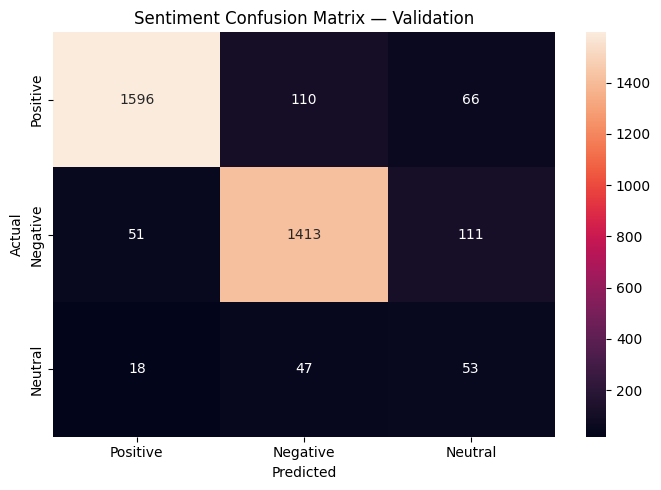

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_sent_val,
    y_sent_val_pred,
    labels=["positive", "negative", "neutral"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Positive", "Negative", "Neutral"],
    yticklabels=["Positive", "Negative", "Neutral"]
)

plt.title("Sentiment Confusion Matrix — Validation")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
baseline_results = {
    "Aspect Micro F1": aspect_micro_f1,
    "Aspect Macro F1": aspect_macro_f1,
    "Aspect Precision": aspect_precision,
    "Aspect Recall": aspect_recall,
    "Aspect Hamming Loss": aspect_hamming,
    "Sentiment Accuracy": sent_accuracy
}

baseline_results

{'Aspect Micro F1': 0.8441116405718175,
 'Aspect Macro F1': 0.8442577693572686,
 'Aspect Precision': 0.8031088082901554,
 'Aspect Recall': 0.8895265423242468,
 'Aspect Hamming Loss': 0.025169675487044213,
 'Sentiment Accuracy': 0.8836940836940836}

In [ ]:
from sklearn.metrics import f1_score

sentiment_macro_f1 = f1_score(
    y_sent_val,
    y_sent_val_pred,
    average="macro"
)

sentiment_weighted_f1 = f1_score(
    y_sent_val,
    y_sent_val_pred,
    average="weighted"
)

print("Sentiment Macro F1:", round(sentiment_macro_f1, 4))
print("Sentiment Weighted F1:", round(sentiment_weighted_f1, 4))

Sentiment Macro F1: 0.7106
Sentiment Weighted F1: 0.8938


In [ ]:
print(type(X_sent_train))
print(type(X_sent_val))

print("X_sent_train shape:", X_sent_train.shape)
print("X_sent_val shape:", X_sent_val.shape)

<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>
X_sent_train shape: (16170,)
X_sent_val shape: (3465,)


In [ ]:
print("Variables containing 'tfidf':")

for name in dir():
    if "tfidf" in name.lower():
        print(name)

Variables containing 'tfidf':
TfidfVectorizer
X_aspect_test_tfidf
X_aspect_train_tfidf
X_aspect_val_tfidf
X_sent_test_tfidf
X_sent_train_tfidf
X_sent_val_tfidf
tfidf


In [ ]:
print("Variables containing 'sent':")

for name in dir():
    if "sent" in name.lower():
        print(name)

Variables containing 'sent':
X_sent_test
X_sent_test_tfidf
X_sent_train
X_sent_train_tfidf
X_sent_val
X_sent_val_tfidf
multi_sentiment
sent_accuracy
sent_indices
sent_temp_idx
sent_test_idx
sent_train_idx
sent_val_idx
sentiment_cols
sentiment_columns
sentiment_counts
sentiment_macro_f1
sentiment_model
sentiment_model_df
sentiment_weighted_f1
sentiments
svm_sentiment
y_sent_test
y_sent_train
y_sent_val
y_sent_val_pred


In [ ]:
print(X_sent_train_tfidf.shape)
print(X_sent_val_tfidf.shape)

(16170, 10000)
(3465, 10000)


In [ ]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

svm_sentiment = LinearSVC(
    class_weight="balanced",
    random_state=42
)

svm_sentiment.fit(
    X_sent_train_tfidf,
    y_sent_train
)

y_svm_sent_val_pred = svm_sentiment.predict(
    X_sent_val_tfidf
)

print("LINEAR SVM — SENTIMENT VALIDATION")
print("=" * 50)

print(
    "Accuracy:",
    round(
        accuracy_score(
            y_sent_val,
            y_svm_sent_val_pred
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_sent_val,
            y_svm_sent_val_pred,
            average="macro"
        ),
        4
    )
)

print(
    "Weighted F1:",
    round(
        f1_score(
            y_sent_val,
            y_svm_sent_val_pred,
            average="weighted"
        ),
        4
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_sent_val,
        y_svm_sent_val_pred,
        digits=4
    )
)

LINEAR SVM — SENTIMENT VALIDATION
Accuracy: 0.9088
Macro F1: 0.7021
Weighted F1: 0.9063

Classification Report:
              precision    recall  f1-score   support

    negative     0.9014    0.9346    0.9177      1575
     neutral     0.2857    0.2203    0.2488       118
    positive     0.9483    0.9317    0.9399      1772

    accuracy                         0.9088      3465
   macro avg     0.7118    0.6956    0.7021      3465
weighted avg     0.9044    0.9088    0.9063      3465



In [ ]:
print("All variables related to TF-IDF:")
for name in dir():
    if "tfidf" in name.lower():
        print(name)

All variables related to TF-IDF:
TfidfVectorizer
X_aspect_test_tfidf
X_aspect_train_tfidf
X_aspect_val_tfidf
X_sent_test_tfidf
X_sent_train_tfidf
X_sent_val_tfidf
tfidf


In [ ]:
svm_sentiment_unbalanced = LinearSVC(
    random_state=42
)

svm_sentiment_unbalanced.fit(
    X_sent_train_tfidf,
    y_sent_train
)

y_svm_unbalanced_pred = svm_sentiment_unbalanced.predict(
    X_sent_val_tfidf
)

print("LINEAR SVM — WITHOUT CLASS WEIGHT")
print("=" * 50)

print(
    "Accuracy:",
    round(
        accuracy_score(
            y_sent_val,
            y_svm_unbalanced_pred
        ),
        4
    )
)

print(
    "Macro F1:",
    round(
        f1_score(
            y_sent_val,
            y_svm_unbalanced_pred,
            average="macro"
        ),
        4
    )
)

print(
    "Weighted F1:",
    round(
        f1_score(
            y_sent_val,
            y_svm_unbalanced_pred,
            average="weighted"
        ),
        4
    )
)

print("\nClassification Report:")

print(
    classification_report(
        y_sent_val,
        y_svm_unbalanced_pred,
        digits=4
    )
)

LINEAR SVM — WITHOUT CLASS WEIGHT
Accuracy: 0.9126
Macro F1: 0.6692
Weighted F1: 0.9026

Classification Report:
              precision    recall  f1-score   support

    negative     0.8947    0.9441    0.9188      1575
     neutral     0.3929    0.0932    0.1507       118
    positive     0.9375    0.9391    0.9383      1772

    accuracy                         0.9126      3465
   macro avg     0.7417    0.6588    0.6692      3465
weighted avg     0.8995    0.9126    0.9026      3465



In [ ]:
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    hamming_loss
)

# Linear SVM for multi-label aspect detection
svm_aspect = OneVsRestClassifier(
    LinearSVC(
        class_weight="balanced",
        random_state=42
    )
)

svm_aspect.fit(
    X_aspect_train_tfidf,
    y_aspect_train
)

# Validation prediction
y_svm_aspect_val_pred = svm_aspect.predict(
    X_aspect_val_tfidf
)

# Evaluation
aspect_svm_micro_f1 = f1_score(
    y_aspect_val,
    y_svm_aspect_val_pred,
    average="micro"
)

aspect_svm_macro_f1 = f1_score(
    y_aspect_val,
    y_svm_aspect_val_pred,
    average="macro"
)

aspect_svm_precision = precision_score(
    y_aspect_val,
    y_svm_aspect_val_pred,
    average="micro",
    zero_division=0
)

aspect_svm_recall = recall_score(
    y_aspect_val,
    y_svm_aspect_val_pred,
    average="micro",
    zero_division=0
)

aspect_svm_hamming = hamming_loss(
    y_aspect_val,
    y_svm_aspect_val_pred
)

print("ASPECT DETECTION — LINEAR SVM")
print("=" * 50)

print("Micro F1:   ", round(aspect_svm_micro_f1, 4))
print("Macro F1:   ", round(aspect_svm_macro_f1, 4))
print("Precision:  ", round(aspect_svm_precision, 4))
print("Recall:     ", round(aspect_svm_recall, 4))
print("Hamming Loss:", round(aspect_svm_hamming, 4))

ASPECT DETECTION — LINEAR SVM
Micro F1:    0.8535
Macro F1:    0.8498
Precision:   0.8348
Recall:      0.873
Hamming Loss: 0.023


In [ ]:
sent_val_proba = sentiment_model.predict_proba(
    X_sent_val_tfidf
)

print("Probability matrix shape:")
print(sent_val_proba.shape)

print("\nClasses:")
print(sentiment_model.classes_)

Probability matrix shape:
(3465, 3)

Classes:
['negative' 'neutral' 'positive']


In [ ]:
import numpy as np
from sklearn.metrics import f1_score, classification_report

# Probability columns
negative_prob = sent_val_proba[:, 0]
neutral_prob = sent_val_proba[:, 1]
positive_prob = sent_val_proba[:, 2]

# Try different thresholds for Neutral
thresholds = np.arange(0.10, 0.51, 0.02)

results = []

for threshold in thresholds:
    y_pred_tuned = []

    for neg, neu, pos in zip(
        negative_prob,
        neutral_prob,
        positive_prob
    ):
        # Give Neutral priority when its probability
        # reaches the selected threshold
        if neu >= threshold:
            pred = "neutral"
        elif pos >= neg:
            pred = "positive"
        else:
            pred = "negative"

        y_pred_tuned.append(pred)

    macro_f1 = f1_score(
        y_sent_val,
        y_pred_tuned,
        average="macro"
    )

    neutral_f1 = f1_score(
        y_sent_val,
        y_pred_tuned,
        labels=["neutral"],
        average="macro"
    )

    accuracy = np.mean(
        np.array(y_sent_val) == np.array(y_pred_tuned)
    )

    results.append({
        "Neutral Threshold": threshold,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Neutral F1": neutral_f1
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.sort_values(
    "Macro F1",
    ascending=False
).head(10))

    Neutral Threshold  Accuracy  Macro F1  Neutral F1
17               0.44  0.887157  0.714180    0.312883
19               0.48  0.890620  0.711181    0.300000
18               0.46  0.887734  0.709571    0.298413
16               0.42  0.882251  0.709359    0.303725
15               0.40  0.880519  0.708566    0.302198
20               0.50  0.891775  0.705205    0.280702
14               0.38  0.875325  0.704463    0.294416
13               0.36  0.870996  0.702949    0.293839
12               0.34  0.866955  0.700080    0.289593
11               0.32  0.859452  0.697207    0.289256


In [ ]:
best_neutral_threshold = 0.44

y_sent_val_tuned = []

for neg, neu, pos in zip(
    negative_prob,
    neutral_prob,
    positive_prob
):
    if neu >= best_neutral_threshold:
        pred = "neutral"
    elif pos >= neg:
        pred = "positive"
    else:
        pred = "negative"

    y_sent_val_tuned.append(pred)

print("Tuned Logistic Regression - Validation Results")
print("=" * 55)

print(classification_report(
    y_sent_val,
    y_sent_val_tuned,
    digits=4
))

print("Macro F1:",
      f1_score(y_sent_val, y_sent_val_tuned, average="macro"))

print("Weighted F1:",
      f1_score(y_sent_val, y_sent_val_tuned, average="weighted"))

Tuned Logistic Regression - Validation Results
              precision    recall  f1-score   support

    negative     0.8970    0.9016    0.8993      1575
     neutral     0.2452    0.4322    0.3129       118
    positive     0.9576    0.9046    0.9304      1772

    accuracy                         0.8872      3465
   macro avg     0.6999    0.7461    0.7142      3465
weighted avg     0.9058    0.8872    0.8952      3465

Macro F1: 0.714180275266607
Weighted F1: 0.8952122307711406


In [ ]:
import joblib

# Save selected models
joblib.dump(svm_aspect, "final_aspect_model.pkl")
joblib.dump(sentiment_model, "final_sentiment_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

# Save selected threshold
best_neutral_threshold = 0.44

print("Final models saved successfully.")
print("Aspect model: Linear SVM")
print("Sentiment model: Logistic Regression")
print("Neutral threshold:", best_neutral_threshold)

Final models saved successfully.
Aspect model: Linear SVM
Sentiment model: Logistic Regression
Neutral threshold: 0.44


In [ ]:
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, hamming_loss

# Predict aspects on the test set
y_aspect_test_pred = svm_aspect.predict(X_aspect_test_tfidf)

# Overall metrics
aspect_test_micro_f1 = f1_score(
    y_aspect_test,
    y_aspect_test_pred,
    average="micro"
)

aspect_test_macro_f1 = f1_score(
    y_aspect_test,
    y_aspect_test_pred,
    average="macro"
)

aspect_test_precision = precision_score(
    y_aspect_test,
    y_aspect_test_pred,
    average="micro"
)

aspect_test_recall = recall_score(
    y_aspect_test,
    y_aspect_test_pred,
    average="micro"
)

aspect_test_hamming = hamming_loss(
    y_aspect_test,
    y_aspect_test_pred
)

print("FINAL ASPECT TEST RESULTS")
print("=" * 50)
print(f"Micro F1   : {aspect_test_micro_f1:.4f}")
print(f"Macro F1   : {aspect_test_macro_f1:.4f}")
print(f"Precision  : {aspect_test_precision:.4f}")
print(f"Recall     : {aspect_test_recall:.4f}")
print(f"Hamming Loss: {aspect_test_hamming:.4f}")

FINAL ASPECT TEST RESULTS
Micro F1   : 0.8525
Macro F1   : 0.8451
Precision  : 0.8354
Recall     : 0.8703
Hamming Loss: 0.0231


In [ ]:
aspect_test_f1 = f1_score(
    y_aspect_test,
    y_aspect_test_pred,
    average=None
)

aspect_test_results = pd.DataFrame({
    "Aspect": aspect_columns,
    "F1 Score": aspect_test_f1
}).sort_values("F1 Score", ascending=False)

print(aspect_test_results.to_string(index=False))

                  Aspect  F1 Score
                    Pool  0.977099
                 Parking  0.959459
                   Wi-Fi  0.953488
               Breakfast  0.948814
                Location  0.944556
                   Noise  0.930435
Bathroom/Shower (toilet)  0.927345
                   Staff  0.922523
                   Clean  0.921801
                     Bed  0.920863
                    Lift  0.916667
                   Beach  0.886076
                    Room  0.791589
                 Comfort  0.787730
          View (Balcony)  0.776860
    Facilities/Amenities  0.767123
       Reception-checkin  0.749186
                     Bar  0.725490
         Value for money  0.705455
     Restaurant (dinner)  0.652632
                 Generic  0.582555


In [ ]:
aspect_test_f1 = f1_score(
    y_aspect_test,
    y_aspect_test_pred,
    average=None
)

aspect_test_results = pd.DataFrame({
    "Aspect": aspect_columns,
    "F1 Score": aspect_test_f1
}).sort_values("F1 Score", ascending=False)

print(aspect_test_results.to_string(index=False))

                  Aspect  F1 Score
                    Pool  0.977099
                 Parking  0.959459
                   Wi-Fi  0.953488
               Breakfast  0.948814
                Location  0.944556
                   Noise  0.930435
Bathroom/Shower (toilet)  0.927345
                   Staff  0.922523
                   Clean  0.921801
                     Bed  0.920863
                    Lift  0.916667
                   Beach  0.886076
                    Room  0.791589
                 Comfort  0.787730
          View (Balcony)  0.776860
    Facilities/Amenities  0.767123
       Reception-checkin  0.749186
                     Bar  0.725490
         Value for money  0.705455
     Restaurant (dinner)  0.652632
                 Generic  0.582555


In [ ]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    confusion_matrix
)

# Get probability predictions on TEST set
sent_test_proba = sentiment_model.predict_proba(
    X_sent_test_tfidf
)

negative_test_prob = sent_test_proba[:, 0]
neutral_test_prob = sent_test_proba[:, 1]
positive_test_prob = sent_test_proba[:, 2]

# Apply the selected Neutral threshold
best_neutral_threshold = 0.44

y_sent_test_tuned = []

for neg, neu, pos in zip(
    negative_test_prob,
    neutral_test_prob,
    positive_test_prob
):
    if neu >= best_neutral_threshold:
        pred = "neutral"
    elif pos >= neg:
        pred = "positive"
    else:
        pred = "negative"

    y_sent_test_tuned.append(pred)

# Final test metrics
sent_test_accuracy = accuracy_score(
    y_sent_test,
    y_sent_test_tuned
)

sent_test_macro_f1 = f1_score(
    y_sent_test,
    y_sent_test_tuned,
    average="macro"
)

sent_test_weighted_f1 = f1_score(
    y_sent_test,
    y_sent_test_tuned,
    average="weighted"
)

print("FINAL SENTIMENT TEST RESULTS")
print("=" * 50)

print(f"Accuracy    : {sent_test_accuracy:.4f}")
print(f"Macro F1    : {sent_test_macro_f1:.4f}")
print(f"Weighted F1 : {sent_test_weighted_f1:.4f}")

print("\nClassification Report")
print("=" * 50)

print(classification_report(
    y_sent_test,
    y_sent_test_tuned,
    digits=4
))

FINAL SENTIMENT TEST RESULTS
Accuracy    : 0.8904
Macro F1    : 0.6943
Weighted F1 : 0.8981

Classification Report
              precision    recall  f1-score   support

    negative     0.8990    0.9098    0.9044      1575
     neutral     0.1949    0.3193    0.2420       119
    positive     0.9630    0.9114    0.9365      1772

    accuracy                         0.8904      3466
   macro avg     0.6856    0.7135    0.6943      3466
weighted avg     0.9076    0.8904    0.8981      3466



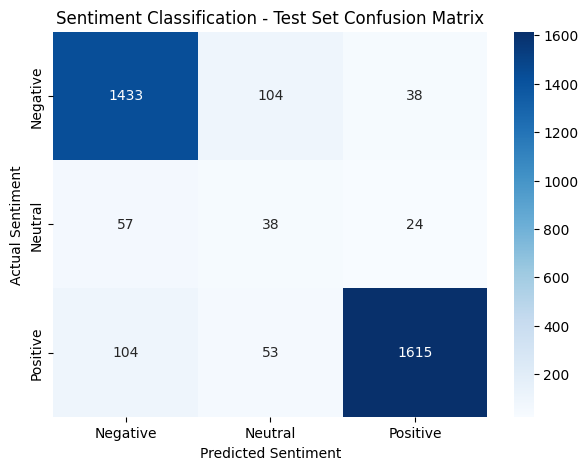

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_sent_test,
    y_sent_test_tuned,
    labels=["negative", "neutral", "positive"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Sentiment Classification - Test Set Confusion Matrix")
plt.show()

In [ ]:
def predict_absa(review):
    # Preprocess review
    processed = preprocess_text(review)

    # Convert to TF-IDF
    review_tfidf = tfidf.transform([processed])

    # -------------------------
    # Aspect prediction
    # -------------------------
    aspect_prediction = svm_aspect.predict(review_tfidf)[0]

    detected_aspects = [
        aspect_columns[i]
        for i, value in enumerate(aspect_prediction)
        if value == 1
    ]

    # -------------------------
    # Sentiment prediction
    # -------------------------
    probabilities = sentiment_model.predict_proba(
        review_tfidf
    )[0]

    neg_prob = probabilities[0]
    neu_prob = probabilities[1]
    pos_prob = probabilities[2]

    if neu_prob >= best_neutral_threshold:
        sentiment = "neutral"
    elif pos_prob >= neg_prob:
        sentiment = "positive"
    else:
        sentiment = "negative"

    # -------------------------
    # Final output
    # -------------------------
    return {
        "review": review,
        "detected_aspects": detected_aspects,
        "sentiment": sentiment,
        "probabilities": {
            "negative": round(float(neg_prob), 4),
            "neutral": round(float(neu_prob), 4),
            "positive": round(float(pos_prob), 4)
        }
    }

In [ ]:
result = predict_absa(
    "The room was clean and comfortable, but the staff were unfriendly."
)

print(result)

{'review': 'The room was clean and comfortable, but the staff were unfriendly.', 'detected_aspects': ['Clean', 'Comfort', 'Staff', 'Room'], 'sentiment': 'positive', 'probabilities': {'negative': 0.0173, 'neutral': 0.119, 'positive': 0.8637}}


In [ ]:
test_reviews = [
    "The room was clean and comfortable.",
    "The staff were rude and unhelpful.",
    "The breakfast was excellent and the location was great.",
    "The bathroom was dirty and the room was very small.",
    "The hotel was okay and nothing was particularly special."
]

for review in test_reviews:
    result = predict_absa(review)

    print("\n" + "=" * 70)
    print("Review:", review)
    print("Aspects:", result["detected_aspects"])
    print("Sentiment:", result["sentiment"])
    print("Probabilities:", result["probabilities"])


Review: The room was clean and comfortable.
Aspects: ['Clean', 'Comfort', 'Room']
Sentiment: positive
Probabilities: {'negative': 0.0016, 'neutral': 0.0011, 'positive': 0.9973}

Review: The staff were rude and unhelpful.
Aspects: ['Staff']
Sentiment: negative
Probabilities: {'negative': 0.7638, 'neutral': 0.0724, 'positive': 0.1638}

Review: The breakfast was excellent and the location was great.
Aspects: ['Location', 'Breakfast']
Sentiment: positive
Probabilities: {'negative': 0.0006, 'neutral': 0.0011, 'positive': 0.9983}

Review: The bathroom was dirty and the room was very small.
Aspects: ['Clean', 'Comfort', 'Room', 'Bathroom/Shower (toilet)']
Sentiment: negative
Probabilities: {'negative': 0.97, 'neutral': 0.0158, 'positive': 0.0143}

Review: The hotel was okay and nothing was particularly special.
Aspects: []
Sentiment: positive
Probabilities: {'negative': 0.1855, 'neutral': 0.2945, 'positive': 0.5201}


In [ ]:
aspect_keywords = {
    "Clean": [
        "clean", "cleanliness", "dirty", "dirt", "spotless", "unclean"
    ],

    "Comfort": [
        "comfortable", "comfort", "uncomfortable", "cozy", "cramped"
    ],

    "Facilities/Amenities": [
        "facilities", "amenities", "facility"
    ],

    "Location": [
        "location", "located", "area", "central", "near", "close"
    ],

    "Restaurant (dinner)": [
        "restaurant", "dinner", "meal", "food"
    ],

    "Staff": [
        "staff", "employee", "employees", "receptionist", "reception"
    ],

    "View (Balcony)": [
        "view", "balcony", "sea view", "city view", "ocean view"
    ],

    "Breakfast": [
        "breakfast", "buffet"
    ],

    "Room": [
        "room", "rooms"
    ],

    "Pool": [
        "pool", "swimming"
    ],

    "Beach": [
        "beach", "sea", "ocean"
    ],

    "Bathroom/Shower (toilet)": [
        "bathroom", "shower", "toilet", "bath", "wc"
    ],

    "Bar": [
        "bar", "drinks"
    ],

    "Bed": [
        "bed", "beds", "mattress", "pillow"
    ],

    "Parking": [
        "parking", "car park", "parking lot"
    ],

    "Noise": [
        "noise", "noisy", "loud", "quiet", "sound"
    ],

    "Reception-checkin": [
        "check-in", "checkin", "checkout", "reception", "front desk"
    ],

    "Lift": [
        "lift", "elevator"
    ],

    "Value for money": [
        "value", "price", "expensive", "cheap", "cost", "worth"
    ],

    "Wi-Fi": [
        "wifi", "wi-fi", "internet"
    ],

    "Generic": [
        "hotel", "property", "place"
    ]
}

print("Aspect keyword dictionary created.")
print("Number of aspects:", len(aspect_keywords))

Aspect keyword dictionary created.
Number of aspects: 21


In [ ]:
import re

def get_aspect_context(review, aspect):
    """
    Extract the sentence/clause containing the detected aspect.
    Keeps punctuation until after sentence splitting.
    """

    # Lowercase while preserving punctuation
    text = str(review).lower().strip()

    # Split into sentences/clauses
    clauses = re.split(
        r"[,.!?;]|\bbut\b|\bhowever\b|\balthough\b|\bthough\b|\bwhile\b",
        text
    )

    clauses = [
        clause.strip()
        for clause in clauses
        if clause.strip()
    ]

    keywords = aspect_keywords.get(aspect, [])

    # Find the smallest relevant clause
    for clause in clauses:
        for keyword in keywords:
            if re.search(
                r"\b" + re.escape(keyword) + r"\b",
                clause
            ):
                return preprocess_text(clause)

    # Fallback to complete review
    return preprocess_text(review)

In [ ]:
review = "The room was clean and comfortable, but the staff were unfriendly."

for aspect in ["Room", "Clean", "Comfort", "Staff"]:
    print(aspect, "→", get_aspect_context(review, aspect))

Room → the room was clean and comfortable
Clean → the room was clean and comfortable
Comfort → the room was clean and comfortable
Staff → the staff were unfriendly


In [ ]:
def predict_aspect_sentiment(review, detected_aspects):
    results = []

    for aspect in detected_aspects:

        # Get local clause/context for this aspect
        context = get_aspect_context(review, aspect)

        # Convert context to TF-IDF
        context_tfidf = tfidf.transform([context])

        # Get sentiment probabilities
        probabilities = sentiment_model.predict_proba(
            context_tfidf
        )[0]

        neg_prob = probabilities[0]
        neu_prob = probabilities[1]
        pos_prob = probabilities[2]

        # Apply selected Neutral threshold
        if neu_prob >= best_neutral_threshold:
            sentiment = "neutral"
        elif pos_prob >= neg_prob:
            sentiment = "positive"
        else:
            sentiment = "negative"

        results.append({
            "Aspect": aspect,
            "Context": context,
            "Sentiment": sentiment,
            "Negative Probability": round(float(neg_prob), 4),
            "Neutral Probability": round(float(neu_prob), 4),
            "Positive Probability": round(float(pos_prob), 4)
        })

    return pd.DataFrame(results)

In [ ]:
review = "The room was clean and comfortable, but the staff were unfriendly."

# Detect aspects
processed = preprocess_text(review)
review_tfidf = tfidf.transform([processed])

aspect_prediction = svm_aspect.predict(review_tfidf)[0]

detected_aspects = [
    aspect_columns[i]
    for i, value in enumerate(aspect_prediction)
    if value == 1
]

# Predict sentiment for each aspect
aspect_results = predict_aspect_sentiment(
    review,
    detected_aspects
)

print("Review:")
print(review)

print("\nAspect-Level Sentiment:")
display(aspect_results)

Review:
The room was clean and comfortable, but the staff were unfriendly.

Aspect-Level Sentiment:


,Aspect,Context,Sentiment,Negative Probability,Neutral Probability,Positive Probability
0,Clean,the room was clean and comfortable,positive,0.0016,0.0011,0.9973
1,Comfort,the room was clean and comfortable,positive,0.0016,0.0011,0.9973
2,Staff,the staff were unfriendly,negative,0.4769,0.1987,0.3244
3,Room,the room was clean and comfortable,positive,0.0016,0.0011,0.9973


In [ ]:
def final_absa(review):

    # ==========================================
    # 1. Preprocess review
    # ==========================================
    processed = preprocess_text(review)
    review_tfidf = tfidf.transform([processed])

    # ==========================================
    # 2. Detect aspects
    # ==========================================
    aspect_prediction = svm_aspect.predict(review_tfidf)[0]

    detected_aspects = [
        aspect_columns[i]
        for i, value in enumerate(aspect_prediction)
        if value == 1
    ]

    # ==========================================
    # 3. Aspect-level sentiment
    # ==========================================
    aspect_results = predict_aspect_sentiment(
        review,
        detected_aspects
    )

    # ==========================================
    # 4. Overall sentence sentiment
    # ==========================================
    probabilities = sentiment_model.predict_proba(
        review_tfidf
    )[0]

    neg_prob = probabilities[0]
    neu_prob = probabilities[1]
    pos_prob = probabilities[2]

    if neu_prob >= best_neutral_threshold:
        overall_sentiment = "neutral"
    elif pos_prob >= neg_prob:
        overall_sentiment = "positive"
    else:
        overall_sentiment = "negative"

    # ==========================================
    # 5. Display final result
    # ==========================================
    print("=" * 70)
    print("ASPECT-BASED SENTIMENT ANALYSIS")
    print("=" * 70)

    print("\nReview:")
    print(review)

    print("\nOverall Sentiment:", overall_sentiment)

    print("\nDetected Aspects:")
    if detected_aspects:
        for aspect in detected_aspects:
            print(" -", aspect)
    else:
        print(" - No specific aspect detected")

    print("\nAspect-Level Sentiment:")

    if len(aspect_results) > 0:
        display(
            aspect_results[
                [
                    "Aspect",
                    "Context",
                    "Sentiment"
                ]
            ]
        )
    else:
        print("No aspect-level sentiment available.")

    print("=" * 70)

    return {
        "review": review,
        "overall_sentiment": overall_sentiment,
        "detected_aspects": detected_aspects,
        "aspect_results": aspect_results
    }

In [ ]:
result = final_absa(
    "The room was clean and comfortable, but the staff were unfriendly."
)

ASPECT-BASED SENTIMENT ANALYSIS

Review:
The room was clean and comfortable, but the staff were unfriendly.

Overall Sentiment: positive

Detected Aspects:
 - Clean
 - Comfort
 - Staff
 - Room

Aspect-Level Sentiment:


,Aspect,Context,Sentiment
0,Clean,the room was clean and comfortable,positive
1,Comfort,the room was clean and comfortable,positive
2,Staff,the staff were unfriendly,negative
3,Room,the room was clean and comfortable,positive


In [ ]:
test_reviews = [
    # 1. Clearly positive
    "The room was spacious, clean and very comfortable. The staff were friendly and helpful.",

    # 2. Clearly negative
    "The room was dirty and small, the bathroom was unpleasant and the staff were rude.",

    # 3. Positive with multiple aspects
    "The location was excellent, breakfast was delicious and the hotel had a beautiful pool.",

    # 4. Negative with multiple aspects
    "The hotel was noisy at night, the bed was uncomfortable and the Wi-Fi was very slow.",

    # 5. Mixed sentiment
    "The room was clean and comfortable, but the staff were unfriendly.",

    # 6. Mixed sentiment with location
    "The hotel was in a great location, but the room was tiny and the bathroom was dirty.",

    # 7. Neutral / mild opinion
    "The room was average and the facilities were nothing special.",

    # 8. Positive service review
    "The reception staff were extremely helpful and check-in was quick and easy.",

    # 9. Negative breakfast review
    "The breakfast was disappointing and there was very little choice.",

    # 10. Positive hotel review
    "Great hotel with excellent facilities, comfortable beds and very friendly staff."
]

for i, review in enumerate(test_reviews, 1):

    result = final_absa(review)

    print(f"\n{'#' * 80}")
    print(f"TEST REVIEW {i}")
    print(f"{'#' * 80}")

    print("Review:")
    print(review)

    print("\nOverall Sentiment:")
    print(result["overall_sentiment"])

    print("\nAspect-Level Results:")

    if len(result["aspect_results"]) > 0:
        display(
            result["aspect_results"][
                ["Aspect", "Sentiment"]
            ]
        )
    else:
        print("No aspects detected.")


ASPECT-BASED SENTIMENT ANALYSIS

Review:
The room was spacious, clean and very comfortable. The staff were friendly and helpful.

Overall Sentiment: positive

Detected Aspects:
 - Clean
 - Comfort
 - Staff
 - Room

Aspect-Level Sentiment:


,Aspect,Context,Sentiment
0,Clean,clean and very comfortable,positive
1,Comfort,clean and very comfortable,positive
2,Staff,the staff were friendly and helpful,positive
3,Room,the room was spacious,positive



################################################################################
TEST REVIEW 1
################################################################################
Review:
The room was spacious, clean and very comfortable. The staff were friendly and helpful.

Overall Sentiment:
positive

Aspect-Level Results:


,Aspect,Sentiment
0,Clean,positive
1,Comfort,positive
2,Staff,positive
3,Room,positive


ASPECT-BASED SENTIMENT ANALYSIS

Review:
The room was dirty and small, the bathroom was unpleasant and the staff were rude.

Overall Sentiment: negative

Detected Aspects:
 - Clean
 - Comfort
 - Staff
 - Bathroom/Shower (toilet)

Aspect-Level Sentiment:


...

,Aspect,Sentiment
0,Breakfast,negative


ASPECT-BASED SENTIMENT ANALYSIS

Review:
Great hotel with excellent facilities, comfortable beds and very friendly staff.

Overall Sentiment: positive

Detected Aspects:
 - Comfort
 - Facilities/Amenities
 - Staff
 - Bed
 - Generic

Aspect-Level Sentiment:


,Aspect,Context,Sentiment
0,Comfort,comfortable beds and very friendly staff,positive
1,Facilities/Amenities,great hotel with excellent facilities,positive
2,Staff,comfortable beds and very friendly staff,positive
3,Bed,comfortable beds and very friendly staff,positive
4,Generic,great hotel with excellent facilities,positive



################################################################################
TEST REVIEW 10
################################################################################
Review:
Great hotel with excellent facilities, comfortable beds and very friendly staff.

Overall Sentiment:
positive

Aspect-Level Results:


,Aspect,Sentiment
0,Comfort,positive
1,Facilities/Amenities,positive
2,Staff,positive
3,Bed,positive
4,Generic,positive


In [ ]:
result = final_absa(
    "The room was clean and comfortable, but the staff were unfriendly."
)

ASPECT-BASED SENTIMENT ANALYSIS

Review:
The room was clean and comfortable, but the staff were unfriendly.

Overall Sentiment: positive

Detected Aspects:
 - Clean
 - Comfort
 - Staff
 - Room

Aspect-Level Sentiment:


,Aspect,Context,Sentiment
0,Clean,the room was clean and comfortable,positive
1,Comfort,the room was clean and comfortable,positive
2,Staff,the staff were unfriendly,negative
3,Room,the room was clean and comfortable,positive


In [ ]:
# ============================================
# FINAL MODEL PERFORMANCE TABLE
# ============================================

final_results = pd.DataFrame({
    "Task": [
        "Aspect Detection",
        "Sentiment Classification"
    ],
    "Model": [
        "One-vs-Rest Linear SVM",
        "Logistic Regression"
    ],
    "Test Accuracy": [
        None,
        sent_test_accuracy
    ],
    "Micro F1": [
        aspect_test_micro_f1,
        None
    ],
    "Macro F1": [
        aspect_test_macro_f1,
        sent_test_macro_f1
    ],
    "Weighted F1": [
        None,
        sent_test_weighted_f1
    ],
    "Precision": [
        aspect_test_precision,
        None
    ],
    "Recall": [
        aspect_test_recall,
        None
    ],
    "Hamming Loss": [
        aspect_test_hamming,
        None
    ]
})

display(
    final_results.style
    .format({
        "Test Accuracy": "{:.4f}",
        "Micro F1": "{:.4f}",
        "Macro F1": "{:.4f}",
        "Weighted F1": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Hamming Loss": "{:.4f}"
    })
)

,Task,Model,Test Accuracy,Micro F1,Macro F1,Weighted F1,Precision,Recall,Hamming Loss
0,Aspect Detection,One-vs-Rest Linear SVM,nan,0.8525,0.8451,nan,0.8354,0.8703,0.0231
1,Sentiment Classification,Logistic Regression,0.8904,nan,0.6943,0.8981,nan,nan,nan


In [ ]:
aspect_test_results

,Aspect,F1 Score
9,Pool,0.977099
14,Parking,0.959459
19,Wi-Fi,0.953488
7,Breakfast,0.948814
3,Location,0.944556
15,Noise,0.930435
11,Bathroom/Shower (toilet),0.927345
5,Staff,0.922523
0,Clean,0.921801
13,Bed,0.920863


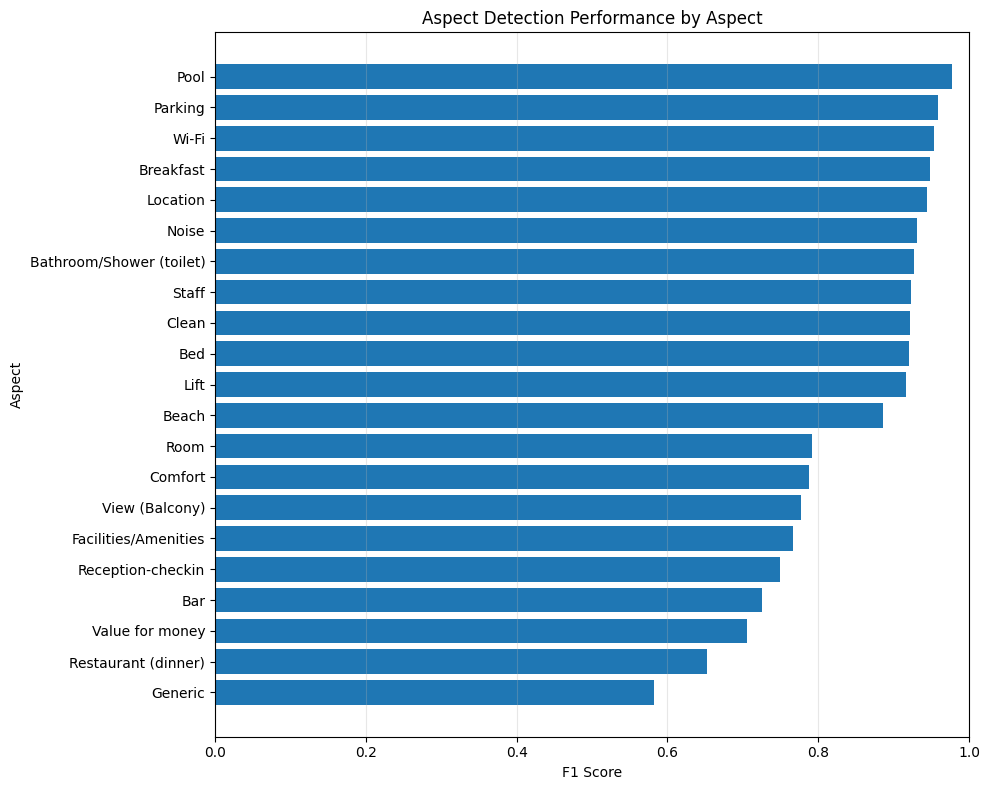

In [ ]:
# ============================================
# ASPECT-WISE F1 SCORE
# ============================================

aspect_plot = aspect_test_results.sort_values(
    "F1 Score",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    aspect_plot["Aspect"],
    aspect_plot["F1 Score"]
)

plt.xlabel("F1 Score")
plt.ylabel("Aspect")
plt.title("Aspect Detection Performance by Aspect")

plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# SENTIMENT CLASS PERFORMANCE
# ============================================

sentiment_report = pd.DataFrame({
    "Sentiment": [
        "Negative",
        "Neutral",
        "Positive"
    ],
    "Precision": [
        0.8990,
        0.1949,
        0.9630
    ],
    "Recall": [
        0.9098,
        0.3193,
        0.9114
    ],
    "F1 Score": [
        0.9044,
        0.2420,
        0.9365
    ]
})

display(
    sentiment_report.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

,Sentiment,Precision,Recall,F1 Score
0,Negative,0.8990,0.9098,0.9044
1,Neutral,0.1949,0.3193,0.2420
2,Positive,0.9630,0.9114,0.9365


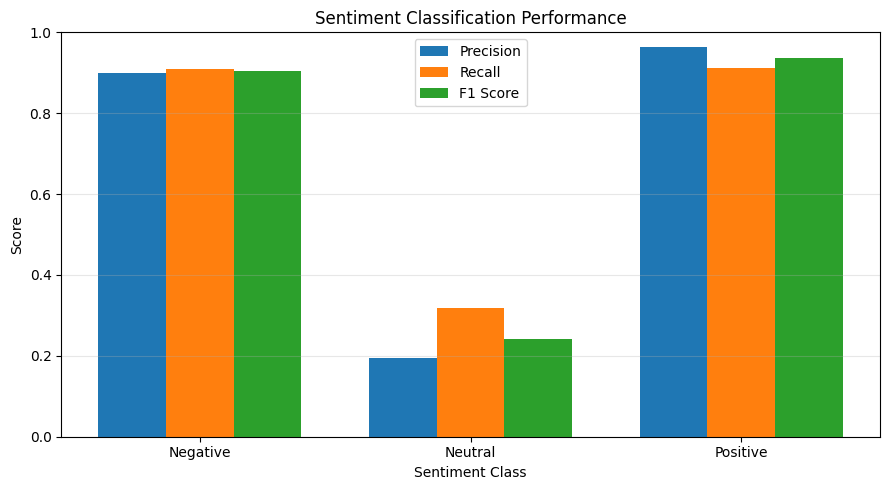

In [ ]:
plt.figure(figsize=(9, 5))

x = np.arange(len(sentiment_report["Sentiment"]))
width = 0.25

plt.bar(
    x - width,
    sentiment_report["Precision"],
    width,
    label="Precision"
)

plt.bar(
    x,
    sentiment_report["Recall"],
    width,
    label="Recall"
)

plt.bar(
    x + width,
    sentiment_report["F1 Score"],
    width,
    label="F1 Score"
)

plt.xticks(
    x,
    sentiment_report["Sentiment"]
)

plt.ylabel("Score")
plt.xlabel("Sentiment Class")
plt.title("Sentiment Classification Performance")

plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

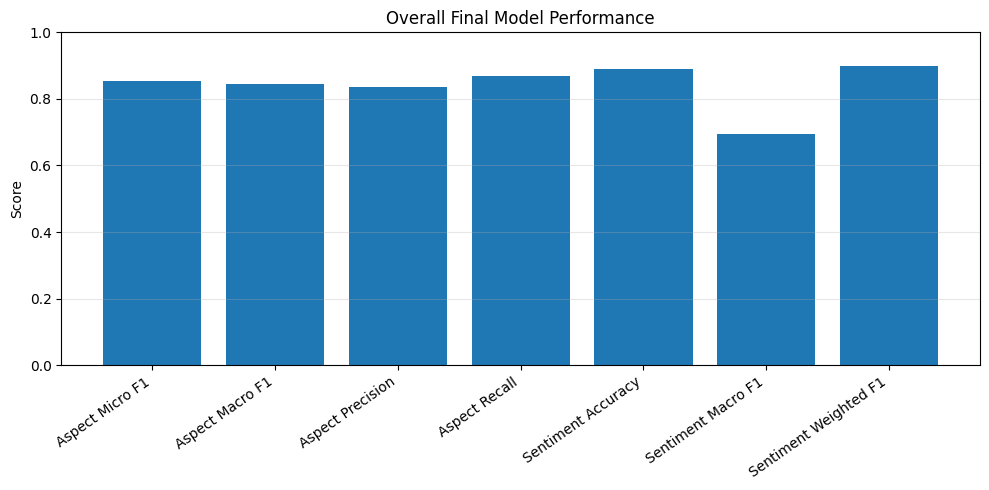

In [ ]:
# ============================================
# OVERALL MODEL PERFORMANCE
# ============================================

overall_metrics = pd.DataFrame({
    "Metric": [
        "Aspect Micro F1",
        "Aspect Macro F1",
        "Aspect Precision",
        "Aspect Recall",
        "Sentiment Accuracy",
        "Sentiment Macro F1",
        "Sentiment Weighted F1"
    ],
    "Score": [
        aspect_test_micro_f1,
        aspect_test_macro_f1,
        aspect_test_precision,
        aspect_test_recall,
        sent_test_accuracy,
        sent_test_macro_f1,
        sent_test_weighted_f1
    ]
})

plt.figure(figsize=(10, 5))

plt.bar(
    overall_metrics["Metric"],
    overall_metrics["Score"]
)

plt.ylabel("Score")
plt.title("Overall Final Model Performance")
plt.ylim(0, 1)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# FINAL PROJECT SUMMARY
# ============================================

project_summary = pd.DataFrame({
    "Component": [
        "Dataset",
        "Number of Reviews",
        "Number of Aspects",
        "Aspect Detection Model",
        "Aspect Test Micro F1",
        "Aspect Test Macro F1",
        "Sentiment Model",
        "Neutral Threshold",
        "Sentiment Test Accuracy",
        "Sentiment Test Macro F1",
        "Sentiment Test Weighted F1"
    ],
    "Result": [
        "HRAST",
        "23,105",
        "21",
        "One-vs-Rest Linear SVM",
        f"{aspect_test_micro_f1:.4f}",
        f"{aspect_test_macro_f1:.4f}",
        "Logistic Regression",
        "0.44",
        f"{sent_test_accuracy:.4f}",
        f"{sent_test_macro_f1:.4f}",
        f"{sent_test_weighted_f1:.4f}"
    ]
})

display(project_summary)

,Component,Result
0,Dataset,HRAST
1,Number of Reviews,"23,105"
2,Number of Aspects,21
3,Aspect Detection Model,One-vs-Rest Linear SVM
4,Aspect Test Micro F1,0.8525
5,Aspect Test Macro F1,0.8451
6,Sentiment Model,Logistic Regression
7,Neutral Threshold,0.44
8,Sentiment Test Accuracy,0.8904
9,Sentiment Test Macro F1,0.6943


In [ ]:
# ============================================
# SAVE FINAL RESULTS
# ============================================

# 1. Save overall model results
final_results.to_csv(
    "final_model_results.csv",
    index=False
)

# 2. Save aspect-wise results
aspect_test_results.to_csv(
    "aspect_wise_results.csv",
    index=False
)

# 3. Save sentiment-wise results
sentiment_report.to_csv(
    "sentiment_class_results.csv",
    index=False
)

# 4. Save project summary
project_summary.to_csv(
    "project_summary.csv",
    index=False
)

print("All final result files saved successfully:")
print("1. final_model_results.csv")
print("2. aspect_wise_results.csv")
print("3. sentiment_class_results.csv")
print("4. project_summary.csv")

All final result files saved successfully:
1. final_model_results.csv
2. aspect_wise_results.csv
3. sentiment_class_results.csv
4. project_summary.csv


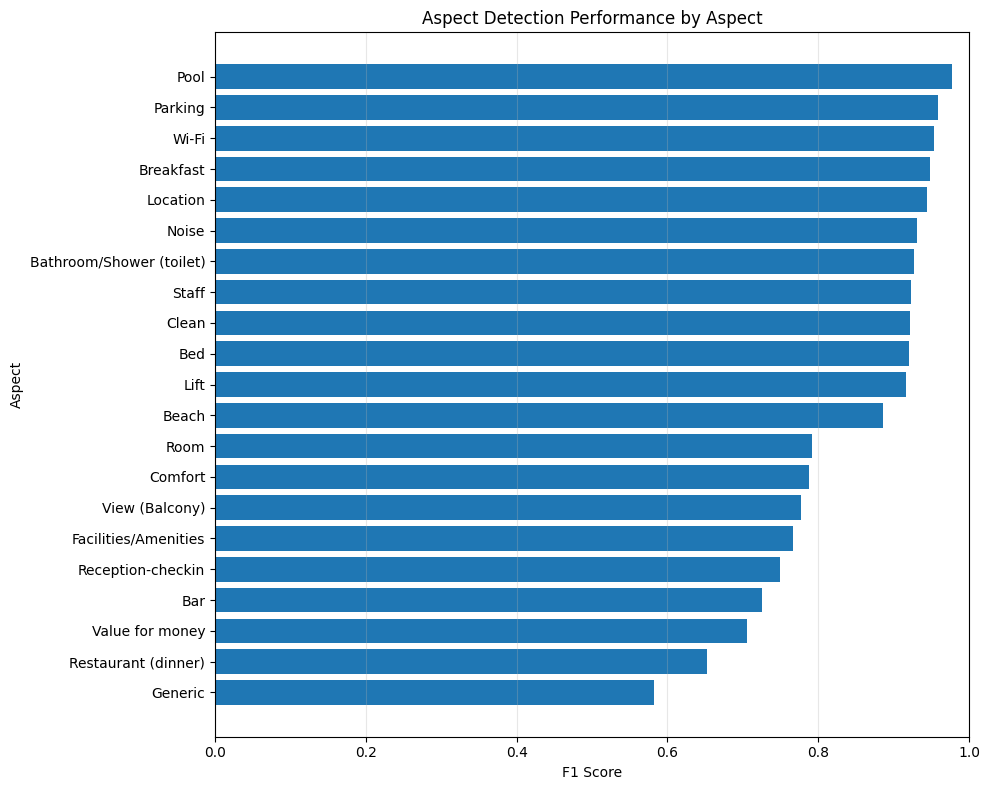

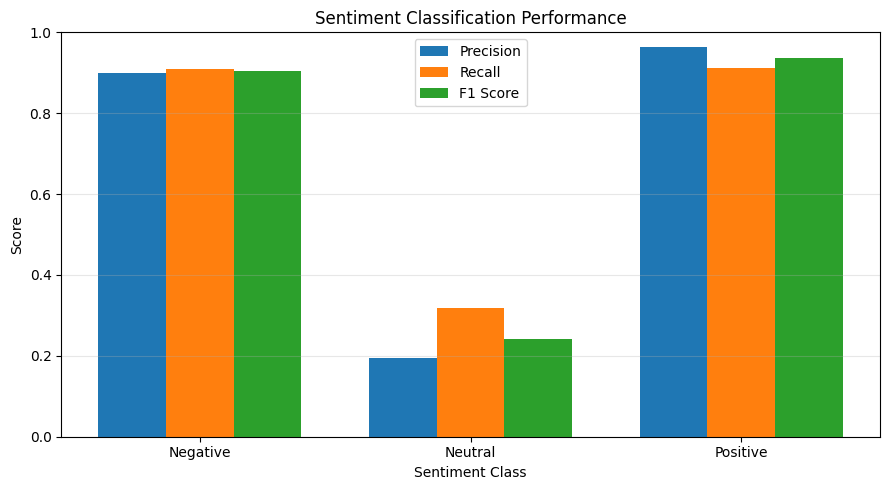

Final figures saved successfully.


In [ ]:
# ============================================
# SAVE FINAL FIGURES
# ============================================

# Aspect performance
plt.figure(figsize=(10, 8))

aspect_plot = aspect_test_results.sort_values(
    "F1 Score",
    ascending=True
)

plt.barh(
    aspect_plot["Aspect"],
    aspect_plot["F1 Score"]
)

plt.xlabel("F1 Score")
plt.ylabel("Aspect")
plt.title("Aspect Detection Performance by Aspect")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "aspect_detection_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Sentiment performance
plt.figure(figsize=(9, 5))

x = np.arange(len(sentiment_report["Sentiment"]))
width = 0.25

plt.bar(
    x - width,
    sentiment_report["Precision"],
    width,
    label="Precision"
)

plt.bar(
    x,
    sentiment_report["Recall"],
    width,
    label="Recall"
)

plt.bar(
    x + width,
    sentiment_report["F1 Score"],
    width,
    label="F1 Score"
)

plt.xticks(x, sentiment_report["Sentiment"])
plt.ylabel("Score")
plt.xlabel("Sentiment Class")
plt.title("Sentiment Classification Performance")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "sentiment_class_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final figures saved successfully.")


In [ ]:
# ============================================================
# ASPECT-BASED SENTIMENT ANALYSIS ON HOTEL REVIEWS
# Final Live Demo
# ============================================================

import re
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# 1. Demo review containing multiple aspects and mixed sentiment
# ------------------------------------------------------------

demo_review = (
    "The room was spacious, clean and very comfortable. "
    "The staff were friendly and helpful, but the bathroom "
    "was dirty and the Wi-Fi was very slow."
)

print("=" * 70)
print("ASPECT-BASED SENTIMENT ANALYSIS ON HOTEL REVIEWS")
print("=" * 70)

print("\nINPUT HOTEL REVIEW:\n")
print(demo_review)

# ------------------------------------------------------------
# 2. Run your trained ABSA pipeline
# ------------------------------------------------------------

# This function should already exist in your notebook.
# It uses your trained aspect model, sentiment model,
# TF-IDF vectorizer, and local-context extraction function.

result = final_absa(demo_review)

# ------------------------------------------------------------
# 3. Display the result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL ABSA OUTPUT")
print("=" * 70)

# final_absa() may print the results and/or return a DataFrame.
if isinstance(result, pd.DataFrame):
    display(result)
elif result is not None:
    print(result)

print("\nDEMO COMPLETED")

ASPECT-BASED SENTIMENT ANALYSIS ON HOTEL REVIEWS

INPUT HOTEL REVIEW:

The room was spacious, clean and very comfortable. The staff were friendly and helpful, but the bathroom was dirty and the Wi-Fi was very slow.


NameError: name 'final_absa' is not defined